In [1]:
import pandas as pd

df = pd.read_csv('../data/telco_churn.csv')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
df.shape

(7043, 21)

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [27]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7032.000000
mean,0.162147,32.371149,64.761692,2283.300441
std,0.368612,24.559481,30.090047,2266.771362
min,0.000000,0.000000,18.250000,18.800000
25%,0.000000,9.000000,35.500000,401.450000
50%,0.000000,29.000000,70.350000,1397.475000
75%,0.000000,55.000000,89.850000,3794.737500
max,1.000000,72.000000,118.750000,8684.800000


In [8]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [9]:
df['TotalCharges'].dtype

dtype('O')

In [10]:
(df['TotalCharges'].str.strip() == '').sum()

np.int64(11)

In [11]:
df.loc[df['TotalCharges'].str.strip() == '', 'tenure']

488     0
753     0
936     0
1082    0
1340    0
3331    0
3826    0
4380    0
5218    0
6670    0
6754    0
Name: tenure, dtype: int64

The initial null-value check shows no explicit missing values in the dataset. However, `TotalCharges` is stored as an object rather than a numerical column, and further inspection identified 11 whitespace-only entries, so this feature requires cleaning before modeling.

In [6]:
df['Churn'].value_counts(normalize=True)

Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')

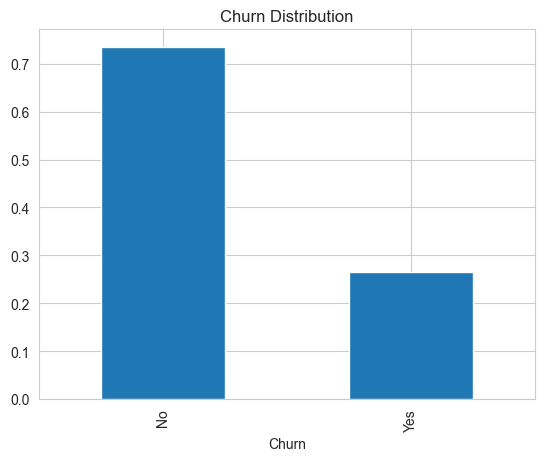

In [14]:
df['Churn'].value_counts(normalize=True).plot(kind='bar', title='Churn Distribution')
plt.show()

The dataset is moderately imbalanced, with approximately 73.5% of customers staying and 26.5% churning. Therefore, accuracy alone may not be sufficient to evaluate the model, paying particular attention to metrics such as precision, recall, F1-score, ROC-AUC, and PR-AUC is required.

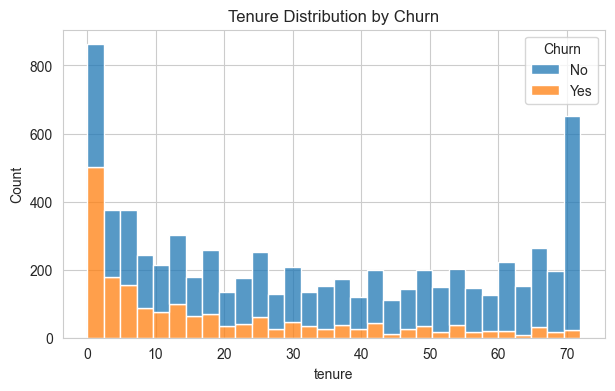

In [15]:
plt.figure(figsize=(7,4))
sns.histplot(data=df, x='tenure', hue='Churn', bins=30, multiple='stack')
plt.title('Tenure Distribution by Churn')
plt.show()

Customers with shorter tenure appear to have a higher concentration of churn, while longer-tenured customers are more concentrated among those who stay. This suggests that tenure may be an important predictor of churn and that newer customers could represent a higher-risk group.

In [32]:
df['Contract'].value_counts()

Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64

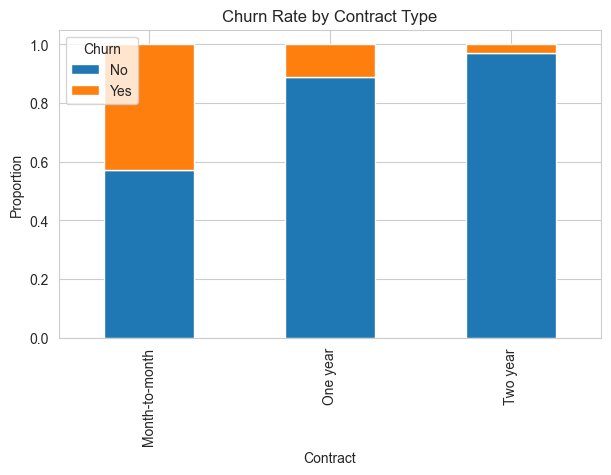

In [16]:
ct = pd.crosstab(df['Contract'], df['Churn'], normalize='index')
ct.plot(kind='bar', stacked=True, figsize=(7,4))
plt.title('Churn Rate by Contract Type')
plt.ylabel('Proportion')
plt.show()

Churn appears substantially higher among customers on month-to-month contracts compared with customers on one-year or two-year contracts. This suggests that contract type may be an important predictor of churn, with customers without a long-term commitment representing a potentially higher-risk segment.

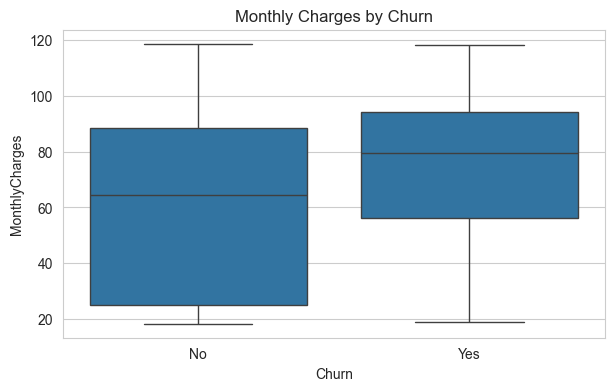

In [17]:
plt.figure(figsize=(7,4))
sns.boxplot(data=df, x='Churn', y='MonthlyCharges')
plt.title('Monthly Charges by Churn')
plt.show()

Customers who churn appear to have higher monthly charges on average than customers who stay. This suggests that monthly charges may contain useful information for predicting churn, although the relationship should be evaluated alongside other customer characteristics.

In [30]:
df['InternetService'].value_counts()

InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

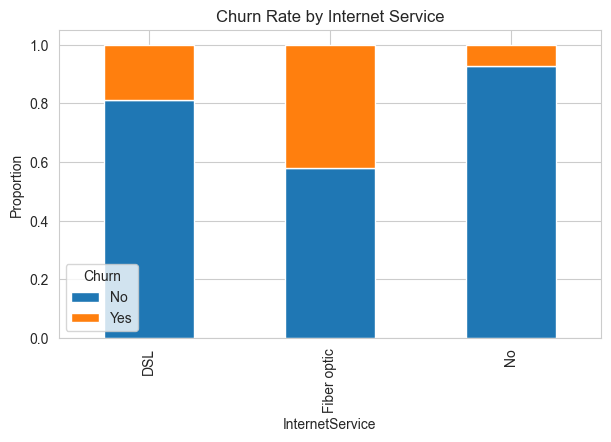

In [19]:
ct_internet = pd.crosstab(df['InternetService'], df['Churn'], normalize='index')
ct_internet.plot(kind='bar', stacked=True, figsize=(7,4))
plt.title('Churn Rate by Internet Service')
plt.ylabel('Proportion')
plt.show()

The churn rate varies across internet service types, indicating that the type of internet service may provide useful information for distinguishing customers with different levels of churn risk. However, this relationship may also be influenced by other customer characteristics.

In [31]:
df['PaymentMethod'].value_counts()

PaymentMethod
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64

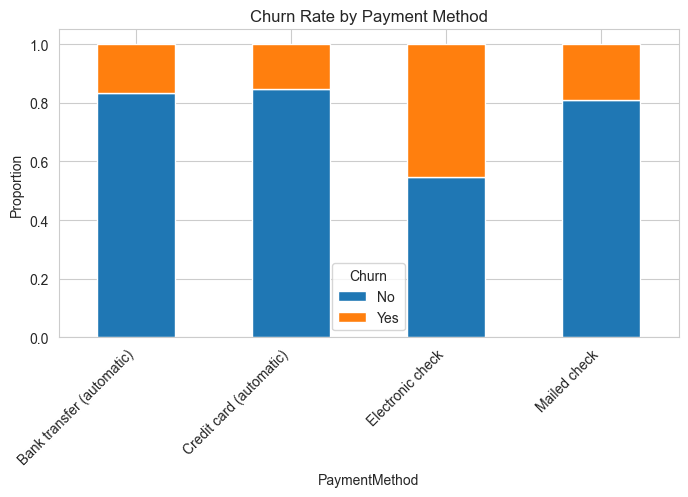

In [20]:
ct_payment = pd.crosstab(df['PaymentMethod'], df['Churn'], normalize='index')
ct_payment.plot(kind='bar', stacked=True, figsize=(8,4))
plt.title('Churn Rate by Payment Method')
plt.ylabel('Proportion')
plt.xticks(rotation=45, ha='right')
plt.show()

Churn rates differ across payment methods, suggesting that payment method may contain predictive information about customer churn. In particular, differences between automatic and non-automatic payment methods may be worth investigating further during modeling.

In [22]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

In [25]:
df['TotalCharges'].dtype

dtype('float64')

In [24]:
df.isnull().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [23]:
numeric_corr = df[['tenure', 'MonthlyCharges', 'TotalCharges']].corr()
numeric_corr

,tenure,MonthlyCharges,TotalCharges
tenure,1.00000,0.247900,0.825880
MonthlyCharges,0.24790,1.000000,0.651065
TotalCharges,0.82588,0.651065,1.000000


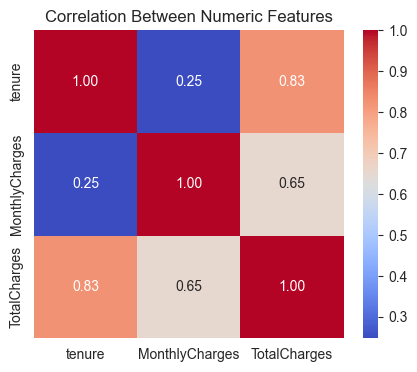

In [26]:
plt.figure(figsize=(5,4))
sns.heatmap(numeric_corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Between Numeric Features')
plt.show()

Tenure and `TotalCharges` show a strong positive relationship, which is expected because customers who have remained with the company longer have had more time to accumulate charges. The relationship between `MonthlyCharges` and `TotalCharges` also reflects the fact that total charges depend partly on the customer's monthly billing amount.